In [1]:
import pandas as pd

In [2]:
df =pd.read_csv(r'C:/Users\New Star Computer 25/DEPI_AI/src\Datasets/Titanic.csv')

In [3]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
df.drop(['PassengerId','Name', 'Ticket'], axis= 1, inplace=True)

In [5]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,NaN,S
887,1,1,female,19.0,0,0,30.0000,B42,S
888,0,3,female,NaN,1,2,23.4500,NaN,S
889,1,1,male,26.0,0,0,30.0000,C148,C


In [6]:
dtypes= df.dtypes
n_uniq= df.nunique()
pd.DataFrame({'Dtypes: ':dtypes, 'Num_Unique': n_uniq})

,Dtypes:,Num_Unique
Survived,int64,2
Pclass,int64,3
Sex,object,2
Age,float64,88
SibSp,int64,7
Parch,int64,7
Fare,float64,248
Cabin,object,147
Embarked,object,3


In [7]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,NaN,S
887,1,1,female,19.0,0,0,30.0000,B42,S
888,0,3,female,NaN,1,2,23.4500,NaN,S
889,1,1,male,26.0,0,0,30.0000,C148,C


In [8]:
num_cols = df[['Age', 'Fare']]
num_cols

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
886,27.0,13.0000
887,19.0,30.0000
888,NaN,23.4500
889,26.0,30.0000


In [9]:
for col in num_cols:
    Q1= df[col].quantile(0.25)
    Q3= df[col].quantile(0.75)
    IQR= Q3-Q1
    lower_fence= Q1- 1.5*IQR
    upper_fence= Q3+ 1.5*IQR
    print(lower_fence)
    print(upper_fence)
    
    lower_outlier= df[ df[col]<lower_fence  ][col].values
    upper_outlier= df[ df[col]>upper_fence  ][col].values

    
    print(lower_outlier)
    
    df[col].replace(lower_outlier, lower_fence)
    df[col].replace(upper_outlier, upper_fence)

    

-6.6875
64.8125
[]
-26.724
65.6344
[]


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

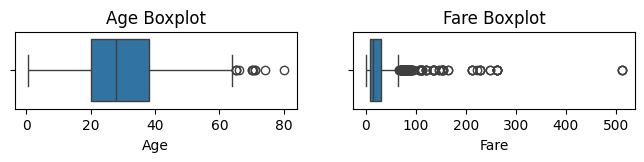

In [11]:
plt.figure(figsize=(8,1))
for i , col in enumerate(num_cols):
    plt.subplot(1,2,i+1)
    sns.boxplot(df[col], orient='h')
    plt.title(f'{col} Boxplot')

In [12]:
def plot_num_boxplot(df):
    num_col=['Age','Fare']
    plt.figure(figsize=(8,1))
    for i , col in enumerate(num_cols):
        plt.subplot(1,2,i+1)
        sns.boxplot(df[col], orient='h')
        plt.title(f'{col} Boxplot')
    
    

In [13]:
df.duplicated().sum()

np.int64(107)

In [14]:
def remove_dup(df,subset_cols=None,keep_strategy='first'):
    return(df.drop_duplicates(subset=subset_cols, keep=keep_strategy ).reset_index(drop=True))

In [15]:
remove_dup(df)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
779,0,3,female,39.0,0,5,29.1250,NaN,Q
780,1,1,female,19.0,0,0,30.0000,B42,S
781,0,3,female,NaN,1,2,23.4500,NaN,S
782,1,1,male,26.0,0,0,30.0000,C148,C


In [16]:
cat_cols= df.select_dtypes('category').columns
plt.figure(figsize=(14,4))
for i , col in enumerate(cat_cols):
    plt.Subplot(2,3,i+1)
    sns.countplot(x=col , data= df)
    plt.title(f'{col} countplot_dist')

<Figure size 1400x400 with 0 Axes>

In [22]:
cat_cols = ['Sex', 'Embarked', 'Pclass']

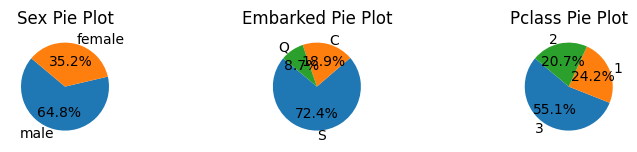

In [23]:
cat_cols

plt.figure(figsize=(9, 4))

for i, col in enumerate(cat_cols):
    plt.subplot(2, 3, i + 1)
    
    unique = df[col].value_counts()
    count = unique.values
    categories = unique.index
    
    plt.pie(
        count,
        labels=categories,
        startangle=140,
        autopct='%1.1f%%'
    )
    
    plt.title(f"{col} Pie Plot")

plt.subplots_adjust(hspace=0.8, wspace=0.3)

plt.show()